In [126]:
# Import the  libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [127]:
# Load the CSV file into a DataFrame
df = pd.read_csv("/content/New_York_City.csv")

In [128]:
# Display the number of rows and columns
df.shape

(48895, 16)

In [129]:
# Display all column names
df.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

In [130]:
# Display the first five rows of the dataset
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [131]:
# Display column names, data types, and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [132]:
# Display numerical columns in the dataset
df.select_dtypes(include="number").columns

Index(['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights',
       'number_of_reviews', 'reviews_per_month',
       'calculated_host_listings_count', 'availability_365'],
      dtype='object')

In [133]:
# Display categorical columns stored as text
df.select_dtypes(include="object").columns

Index(['name', 'host_name', 'neighbourhood_group', 'neighbourhood',
       'room_type', 'last_review'],
      dtype='object')

In [134]:
# Count missing values in each column
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [135]:
# Calculate the percentage of missing values in each column
(df.isnull().sum() / len(df)) * 100

,0
id,0.000000
name,0.032723
host_id,0.000000
host_name,0.042949
neighbourhood_group,0.000000
neighbourhood,0.000000
latitude,0.000000
longitude,0.000000
room_type,0.000000
price,0.000000


In [136]:
missing_table = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

In [137]:
# Display only columns that contain missing values
missing_table = missing_table[missing_table["Missing Values"] > 0]

In [138]:
# Display the missing-value report rounded to two decimal places
missing_table.round(2)

,Missing Values,Missing Percentage
name,16,0.03
host_name,21,0.04
last_review,10052,20.56
reviews_per_month,10052,20.56


In [139]:
# Task 2.1: Handle the last_review Column
# Check the number of missing values in the last_review column
df['last_review'].isnull().sum()

np.int64(10052)

In [140]:
# Drop the last_review column because it contains many missing values
df = df.drop(columns=["last_review"])

In [141]:
# Task 2.2: Handle Missing Values in reviews_per_month
# Check the number of missing values in reviews_per_month
df["reviews_per_month"].isnull().sum()

np.int64(10052)

In [142]:
# Check the number of reviews for listings with missing monthly reviews
df[df["reviews_per_month"].isnull()]["number_of_reviews"].value_counts()

,count
number_of_reviews,
0,10052


In [143]:
# Replace missing monthly review values with zero for listings
df.loc[
    (df["reviews_per_month"].isnull()) &
    (df["number_of_reviews"] == 0),
    "reviews_per_month"
] = 0

In [144]:
# Fill any remaining missing values with the median value
df["reviews_per_month"] = df["reviews_per_month"].fillna(
    df["reviews_per_month"].median()
)

In [145]:
# Check whether missing values remain in reviews_per_month
df["reviews_per_month"].isnull().sum()

np.int64(0)

In [146]:
# Task 2.3: Drop Irrelevant Identifier Columns
# Remove identifiers and descriptive columns that will not be used
df = df.drop(columns=[
    "id",
    "host_id",
    "name",
    "host_name"
])

In [147]:
# Display the remaining column names after cleaning
df.columns

Index(['neighbourhood_group', 'neighbourhood', 'latitude', 'longitude',
       'room_type', 'price', 'minimum_nights', 'number_of_reviews',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

In [148]:
# Check the number of missing values remaining in every column
df.isnull().sum()

,0
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0
minimum_nights,0
number_of_reviews,0
reviews_per_month,0
calculated_host_listings_count,0


In [149]:
# Display the first five rows of the cleaned dataset
df.head()

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,0.21,6,365
1,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,0.38,2,355
2,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,0.00,1,365
3,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,4.64,1,194
4,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,0.10,1,0


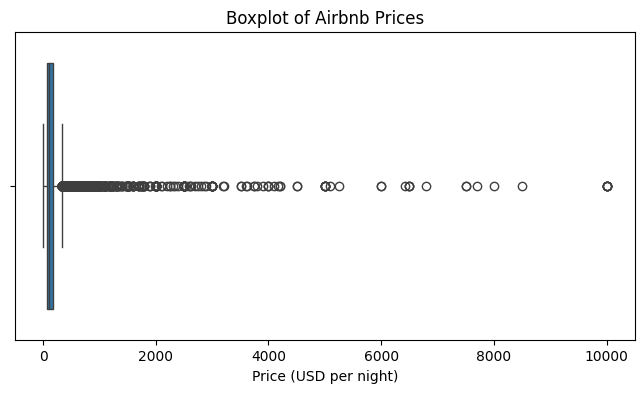

In [150]:
#Task 3.1: Create boxplots and histograms

# Create a boxplot to identify outliers in Airbnb prices
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["price"])
plt.title("Boxplot of Airbnb Prices")
plt.xlabel("Price (USD per night)")
plt.show()


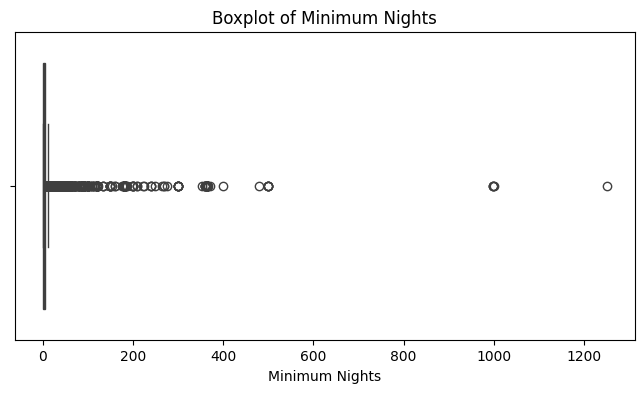

In [151]:
# Create a boxplot to identify outliers in minimum nights
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["minimum_nights"])
plt.title("Boxplot of Minimum Nights")
plt.xlabel("Minimum Nights")
plt.show()

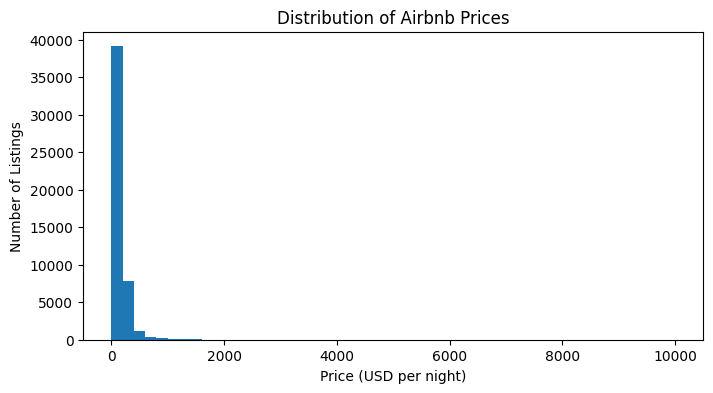

In [152]:
# Create a histogram to examine the distribution of Airbnb prices
plt.figure(figsize=(8, 4))
plt.hist(df["price"], bins=50)
plt.title("Distribution of Airbnb Prices")
plt.xlabel("Price (USD per night)")
plt.ylabel("Number of Listings")
plt.show()

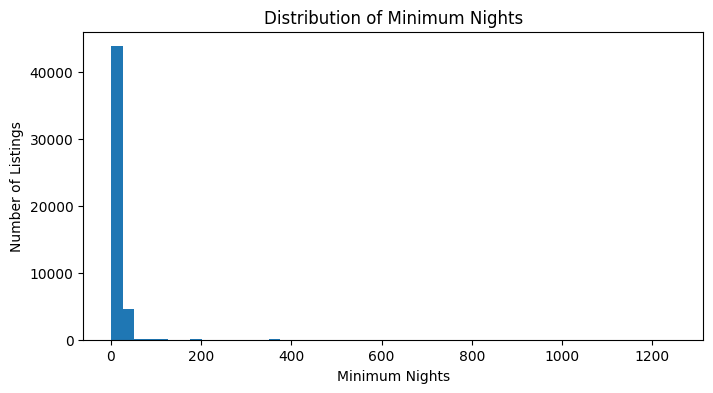

In [153]:
# Create a histogram to examine the distribution of minimum nights
plt.figure(figsize=(8, 4))
plt.hist(df["minimum_nights"], bins=50)
plt.title("Distribution of Minimum Nights")
plt.xlabel("Minimum Nights")
plt.ylabel("Number of Listings")
plt.show()

In [154]:
#Task 3.2: Remove extreme outliers
# Calculate the 95th percentile of Airbnb prices
price_95 = df["price"].quantile(0.95)

In [155]:
# Remove listings with prices above the 95th percentile
# Remove listings with zero or negative prices
# Remove listings requiring 365 nights or more
df = df[
    (df["price"] > 0) &
    (df["price"] <= price_95) &
    (df["minimum_nights"] < 365)
]

In [156]:
# Display the number of rows and columns after outlier treatment
df.shape

(46406, 11)

In [157]:
# Display summary statistics for price and minimum nights after cleaning
df[["price", "minimum_nights"]].describe()

,price,minimum_nights
count,46406.000000,46406.000000
mean,122.599448,6.580852
std,71.968762,13.857411
min,10.000000,1.000000
25%,65.000000,1.000000
50%,100.000000,2.000000
75%,160.000000,5.000000
max,355.000000,364.000000


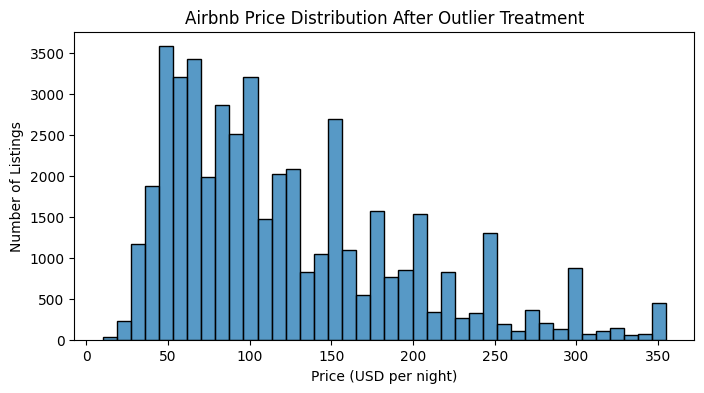

In [158]:
# Plot the price distribution after removing extreme outliers
plt.figure(figsize=(8, 4))
sns.histplot(df["price"], bins=40)
plt.title("Airbnb Price Distribution After Outlier Treatment")
plt.xlabel("Price (USD per night)")
plt.ylabel("Number of Listings")
plt.show()

In [159]:
#Task 4.1: Remove the high-cardinality column
# Check the number of unique neighbourhoods
df["neighbourhood"].nunique()

219

In [160]:
# Drop neighbourhood because it contains too many unique categories
df = df.drop(columns=["neighbourhood"])

In [122]:
# Display the remaining column names
df.columns

Index(['latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365', 'neighbourhood_group_Brooklyn',
       'neighbourhood_group_Manhattan', 'neighbourhood_group_Queens',
       'neighbourhood_group_Staten Island', 'room_type_Private room',
       'room_type_Shared room'],
      dtype='object')

In [161]:
# Convert categorical columns into numerical columns
# drop_first=True removes one category from each group
df = pd.get_dummies(
    df,
    columns=["neighbourhood_group", "room_type"],
    drop_first=True,
    dtype=int
)

In [162]:
# Display the first five rows after encoding
df.head()

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,149,1,9,0.21,6,365,1,0,0,0,1,0
1,40.75362,-73.98377,225,1,45,0.38,2,355,0,1,0,0,0,0
2,40.80902,-73.94190,150,3,0,0.00,1,365,0,1,0,0,1,0
3,40.68514,-73.95976,89,1,270,4.64,1,194,1,0,0,0,0,0
4,40.79851,-73.94399,80,10,9,0.10,1,0,0,1,0,0,0,0


In [163]:
# Check the dimensions of the dataset after encoding
df.shape

(46406, 14)

In [164]:
# Check the data types of all remaining columns
df.dtypes

,0
latitude,float64
longitude,float64
price,int64
minimum_nights,int64
number_of_reviews,int64
reviews_per_month,float64
calculated_host_listings_count,int64
availability_365,int64
neighbourhood_group_Brooklyn,int64
neighbourhood_group_Manhattan,int64


In [165]:
# Feature-Target Separation and Train-Test Split
# Task 5.1: Separate the input features and target variable

# Select all columns except price as input features
X = df.drop(columns=["price"])

In [166]:
# Select price as the target variable to predict
y = df["price"]

In [167]:
# Display the dimensions of the feature data
X.shape

(46406, 13)

In [168]:
# Display the dimensions of the target data
y.shape

(46406,)

In [204]:
# Task 5.2: Import the function for splitting the dataset
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [173]:
# Display the dimensions of the training features
X_train.shape



(37124, 13)

In [174]:
# Display the dimensions of the testing features
X_test.shape

(9282, 13)

In [175]:
# Display the dimensions of the training target
y_train.shape

(37124,)

In [176]:
# Display the dimensions of the testing target
y_test.shape

(9282,)

In [177]:
# Check whether the training set contains approximately 80% of the data
len(X_train) / len(X) * 100

79.998276084989

In [178]:
# Check whether the testing set contains approximately 20% of the data
len(X_test) / len(X) * 100

20.00172391501099

In [179]:
# Model Training and Evaluation

# Task 6.1: Import the Linear Regression algorithm

from sklearn.linear_model import LinearRegression

In [180]:
# Create a Linear Regression model
model = LinearRegression()

In [181]:
# Train the model using the training data
model.fit(X_train, y_train)

LinearRegression()

In [182]:
# Display the trained model
model

LinearRegression()

In [183]:
# Task 6.2: Predict Airbnb prices using the testing features
y_pred = model.predict(X_test)

In [184]:
# Display the first ten predicted prices
y_pred[:10]

array([102.41538914, 149.63635394,  86.85541368,  90.12502135,
       148.73435176, 186.2190899 ,  65.06427165, 108.97148327,
        59.71925912, 166.44921498])

In [185]:
# Task 6.3: Import the evaluation metrics
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error


In [186]:
# Calculate the R-squared score
r2 = r2_score(y_test, y_pred)

In [187]:
# Calculate the Mean Absolute Error
mae = mean_absolute_error(y_test, y_pred)

In [188]:
# Calculate the Mean Squared Error
mse = mean_squared_error(y_test, y_pred)

In [189]:
# Calculate the Root Mean Squared Error
rmse = mse ** 0.5

In [190]:
# Display the R-squared score
r2

0.46987232647451616

In [191]:
# Display the Mean Absolute Error in US dollars
mae

38.14059542509071

In [192]:
# Display the Root Mean Squared Error in US dollars
rmse

52.1257633733922

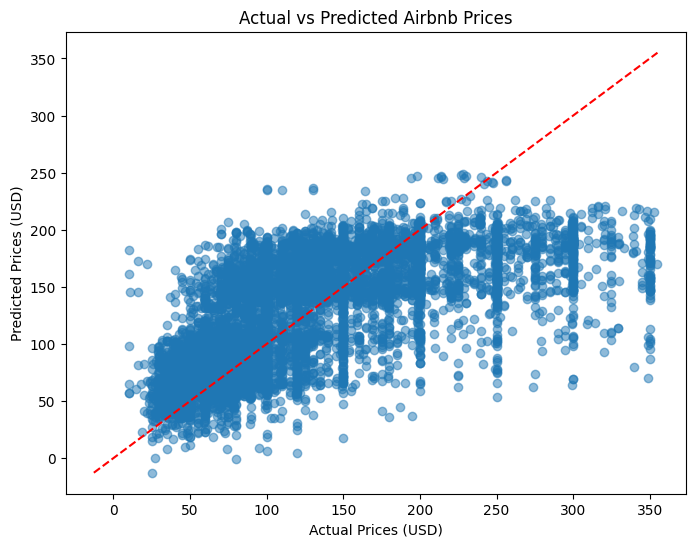

In [200]:
# Residual Analysis and Interpretation
# Task 7.1: Import Matplotlib for plotting
import matplotlib.pyplot as plt

# Create a scatter plot of actual and predicted prices
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)

# Calculate the range for the reference line
lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

# Draw the 45-degree line representing perfect predictions
plt.plot([lower, upper], [lower, upper], "r--")

# Add labels and title
plt.xlabel("Actual Prices (USD)")
plt.ylabel("Predicted Prices (USD)")
plt.title("Actual vs Predicted Airbnb Prices")

# Display the graph
plt.show()

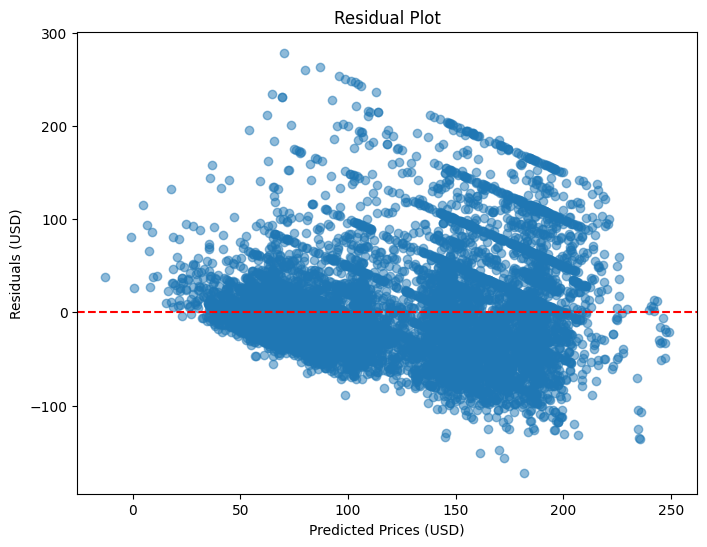

In [201]:
# Task 7.2: Calculate residuals as actual price minus predicted price
residuals = y_test - y_pred

# Create a residual plot
plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, alpha=0.5)

# Draw a horizontal line at zero error
plt.axhline(y=0, color="red", linestyle="--")

# Add labels and title
plt.xlabel("Predicted Prices (USD)")
plt.ylabel("Residuals (USD)")
plt.title("Residual Plot")

# Display the graph
plt.show()

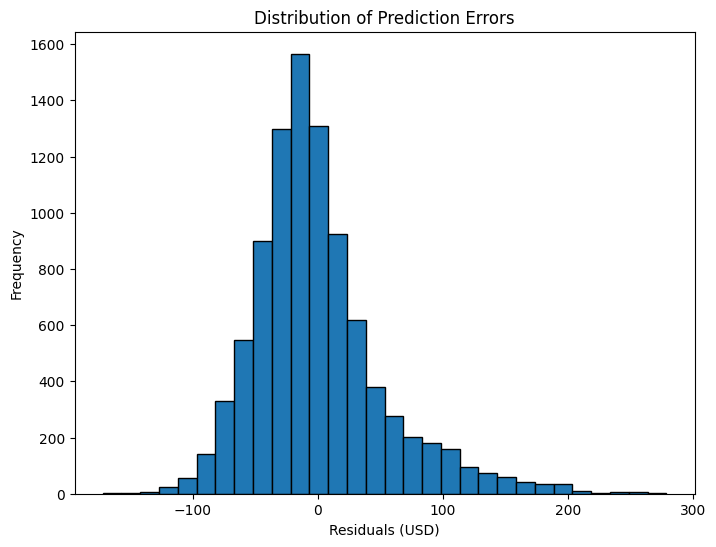

In [205]:
# Plot the distribution of prediction errors
plt.figure(figsize=(8, 6))
plt.hist(residuals, bins=30, edgecolor="black")

# Add labels and title
plt.xlabel("Residuals (USD)")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors")

# Display the graph
plt.show()

In [206]:
# Task 7.3: Create a table containing actual and predicted prices
results = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": y_pred
})

# Calculate the absolute prediction error for each listing
results["Absolute Error"] = (
    results["Actual Price"] - results["Predicted Price"]
).abs()

# Divide listings into cheaper and more expensive groups
median_price = results["Actual Price"].median()

results["Price Group"] = results["Actual Price"].apply(
    lambda price: "Cheaper Listings"
    if price <= median_price
    else "Expensive Listings"
)

# Calculate the average absolute error for each group
comparison = results.groupby("Price Group").agg(
    Number_of_Listings=("Actual Price", "count"),
    Average_Actual_Price=("Actual Price", "mean"),
    MAE=("Absolute Error", "mean")
)

# Display the comparison results
comparison.round(2)

,Number_of_Listings,Average_Actual_Price,MAE
Price Group,,,
Cheaper Listings,4839,67.94,29.48
Expensive Listings,4443,180.36,47.58


In [207]:
# Calculate absolute percentage error for each listing
results["Percentage Error"] = (
    results["Absolute Error"] / results["Actual Price"]
) * 100

# Calculate average percentage error for each price group
percentage_comparison = results.groupby("Price Group")[
    "Percentage Error"
].mean()

# Display average percentage errors
percentage_comparison.round(2)

,Percentage Error
Price Group,
Cheaper Listings,48.93
Expensive Listings,25.14
